**Load Data**

Load Hotel_Booking/hotel_bookings.csv file provided on Brightspace.

In [1]:
!pip install numpy matplotlib seaborn pandas openpyxl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import StackingRegressor
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import numpy as np

# 1. Data Pre-processing (25%)


---






**Drop irrelevant columns**

It will significantly reduce the time and effort you need to invest. As a general guideline, columns containing IDs, dates, or irrelevant information are typically considered redundant and offer little value for predictive analysis.

In [2]:
wqi_data = pd.read_excel('./WQI.xlsx')

In [3]:
print("Dataset from file WQI:")
print(wqi_data.head())

Dataset from file WQI:
     Month  Year Location  NH4+_N  NO2-_N  Temperature   pH  COD   DO  \
0  Tháng 1  2023      SG1    0.50   0.014         26.8  7.1    6  4.5   
1  Tháng 2  2023      SG1    0.02   0.017         28.8  6.8   18  3.5   
2  Tháng 3  2023      SG1    0.01   0.010         28.6  6.8    8  3.5   
3  Tháng 4  2023      SG1    0.03   0.019         28.9  6.8    4  3.7   
4  Tháng 5  2023      SG1    0.01   0.040         29.8  6.9   18  2.5   

   Coliform        WQI  
0    2100.0  19.901415  
1    1500.0  19.376703  
2    2800.0  18.395528  
3    2100.0  20.581375  
4    2800.0  17.114290  


Month: Monitoring month

Year: Monitoring year

Location: Sampling location

NH4+_N: Ammonium Nitrogen concentration

NO2-_N: Nitrite Nitrogen concentration

Temperature: Measured temperature

pH: pH Level

COD: Chemical Oxygen Demand

DO: Dissolved Oxygen

Coliform: Coliform count

WQI: Water Quality Index (pre-calculated)

## Unique values

Find out unique values in columns. This will help you in identifying in-consistent data.

In [4]:
# <<< Your code here >>>

## 1.1 Missing Values (10%)

Identify and handle missing values.

In [5]:
# Check the total number of missing values in the entire DataFrame
missing_data = wqi_data.isnull().sum()
print("Number of missing values in each column:\n", missing_data)

# Remove rows that contain NaN values
wqi_data_cleaned = wqi_data.dropna()

# Convert data to numeric type
numeric_columns = ['NH4+_N', 'NO2-_N', 'Temperature', 'pH', 'COD', 'DO', 'Coliform', 'WQI']
for col in numeric_columns:
    wqi_data_cleaned[col] = pd.to_numeric(wqi_data_cleaned[col], errors='coerce')

Number of missing values in each column:
 Month          0
Year           0
Location       0
NH4+_N         0
NO2-_N         0
Temperature    0
pH             0
COD            0
DO             1
Coliform       3
WQI            4
dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_12352\899098800.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wqi_data_cleaned[col] = pd.to_numeric(wqi_data_cleaned[col], errors='coerce')


In [6]:
df = pd.DataFrame(wqi_data_cleaned)
# View the filtered DataFrame
print("Filtered DataFrame:")
print(df)

# Check the total number of missing values
missing_data = df.isnull().sum()
print("Number of missing values in each column:\n", missing_data)

Filtered DataFrame:
        Month  Year Location  NH4+_N  NO2-_N  Temperature   pH  COD   DO  \
0     Tháng 1  2023      SG1    0.50   0.014         26.8  7.1    6  4.5   
1     Tháng 2  2023      SG1    0.02   0.017         28.8  6.8   18  3.5   
2     Tháng 3  2023      SG1    0.01   0.010         28.6  6.8    8  3.5   
3     Tháng 4  2023      SG1    0.03   0.019         28.9  6.8    4  3.7   
4     Tháng 5  2023      SG1    0.01   0.040         29.8  6.9   18  2.5   
..        ...   ...      ...     ...     ...          ...  ...  ...  ...   
437   Tháng 9  2023     RTT2    1.00   0.126         28.6  6.3   16  1.7   
438  Tháng 10  2023     RTT2    0.60   0.085         28.2  6.7    4  2.7   
439  Tháng 11  2023     RTT2    0.43   0.015         28.3  6.5   10  2.4   
440  Tháng 12  2023     RTT2    0.96   0.097         27.7  6.6    8  2.6   
441   Tháng 1  2024     RTT2    0.53   0.082         28.1  6.6    8  4.2   

     Coliform        WQI  
0      2100.0  19.901415  
1      1500.0

In [7]:
columns_of_interest = ['Month', 'Year', 'Location', 'NH4+_N', 'NO2-_N', 'Temperature', 'pH', 'COD', 'DO', 'Coliform', 'WQI']
final_data = wqi_data_cleaned[columns_of_interest]

print("Cleaned and selected WQI data:")
print(final_data)

Cleaned and selected WQI data:
        Month  Year Location  NH4+_N  NO2-_N  Temperature   pH  COD   DO  \
0     Tháng 1  2023      SG1    0.50   0.014         26.8  7.1    6  4.5   
1     Tháng 2  2023      SG1    0.02   0.017         28.8  6.8   18  3.5   
2     Tháng 3  2023      SG1    0.01   0.010         28.6  6.8    8  3.5   
3     Tháng 4  2023      SG1    0.03   0.019         28.9  6.8    4  3.7   
4     Tháng 5  2023      SG1    0.01   0.040         29.8  6.9   18  2.5   
..        ...   ...      ...     ...     ...          ...  ...  ...  ...   
437   Tháng 9  2023     RTT2    1.00   0.126         28.6  6.3   16  1.7   
438  Tháng 10  2023     RTT2    0.60   0.085         28.2  6.7    4  2.7   
439  Tháng 11  2023     RTT2    0.43   0.015         28.3  6.5   10  2.4   
440  Tháng 12  2023     RTT2    0.96   0.097         27.7  6.6    8  2.6   
441   Tháng 1  2024     RTT2    0.53   0.082         28.1  6.6    8  4.2   

     Coliform        WQI  
0      2100.0  19.901415  
1 

## 1.2 Removing Inconsistent values and Outliers (10%)

Detecting inconsistencies can be achieved through a variety of methods. Some can be identified by examining unique values within each column, while others may require a solid understanding of the problem domain. Since you might not be an expert in the hotel or hospitality industry, here are some helpful hints:

Hints:

1. Check for incomplete bookings, such as reservations with zero adults, babies, or children.
2. Examine rows with zeros in both 'stays_in_weekend_nights' and 'stays_in_week_nights.'



## 1.3 Column data type conversion (5%)

All necessary columns should be correctly converted to appropriate data types.


In [8]:
# <<< Your code here >>>

# 2. Exploratory Data Analysis (25%)


---





You've also been provided with examples of valuable insights that could be of interest to hotel management, including:

* Calculating cancellation percentages for City and Resort hotels.
* Identifying the most frequently ordered meal types.
* Determining the number of returning guests.
* Discovering the most booked room types.
* Exploring correlations between room types and cancellations.


For each of these tasks, choose a suitable type of visualisation covered in
the practical sessions, such as:

* Bar graphs
* Pie charts
* Line charts
* Heatmaps

Text(0.5, 1.0, 'Distribution of NH4+_N')

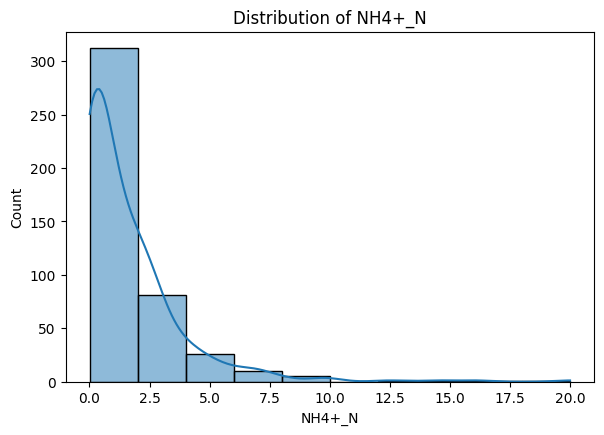

In [9]:
plt.figure(figsize=(15, 10))
# Distribution plot for NH4+_N
plt.subplot(2, 2, 1)
sns.histplot(final_data['NH4+_N'], bins=10, kde=True)
plt.title('Distribution of NH4+_N')

Horizontal axis: Represents NH4+_N values in the water samples.

Vertical axis: Represents the number of samples (Count) within each NH4+_N range.

Observations:

- Most NH4+_N values are concentrated around the range of 0 to 2, indicating this is the common concentration range of Ammonium in the water samples.

- The histogram shows a right-skewed distribution, meaning that most NH4+_N values are low, but there are still a few samples with higher values.

- The data has a clear peak around 1.0, indicating a strong concentration at this level, but there are still a few samples with higher NH4+_N values, reaching up to approximately 20.

Text(0.5, 1.0, 'Phân phối NO2-_N')

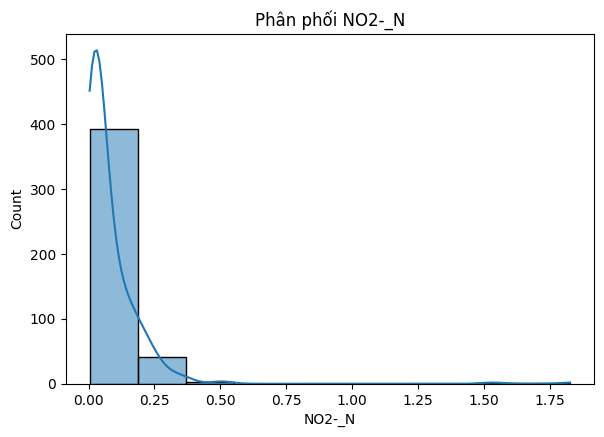

In [10]:
plt.figure(figsize=(15, 10))
# Biểu đồ phân phối cho NO2-_N
plt.subplot(2, 2, 2)
sns.histplot(final_data['NO2-_N'], bins=10, kde=True)
plt.title('Phân phối NO2-_N')

Horizontal axis: Represents the values of NH4+_N in the water samples.

Vertical axis: Represents the number of samples (Count) within each value range of NH4+_N.

Observations:

- Most NH4+_N values are concentrated around the range from 0 to 2, indicating that this is the common concentration range of Ammonium in the water samples.

- The chart shows a right-skewed distribution, meaning that most NH4+_N values are low, but there are still some samples with higher values.

- The data has a clear peak around approximately 1.0, showing a strong concentration at this level, but there are still a few samples with NH4+_N values higher than this, reaching up to around 20.

Text(0.5, 1.0, 'Temperature Distribution')

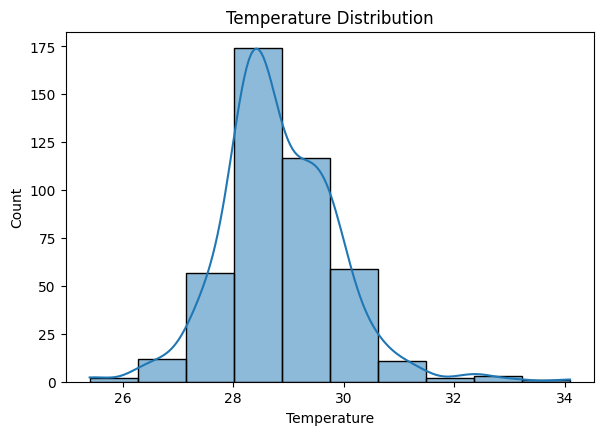

In [11]:
plt.figure(figsize=(15, 10))
# Distribution plot for Temperature
plt.subplot(2, 2, 1)
sns.histplot(final_data['Temperature'], bins=10, kde=True)
plt.title('Temperature Distribution')

Horizontal axis (x-axis): Temperature values (°C).

Vertical axis (y-axis): Number of samples (Count) within each temperature range.

Blue line: The probability density curve (KDE) showing the distribution trend of the data.

Observations:

- Most Temperature values are concentrated around 28.0°C to 28.5°C, indicating that this is the common temperature in the collected water samples.

- The distribution has an approximately bell-shaped form, with some extreme values on both sides, which may indicate temperature variations under different environmental conditions.

Text(0.5, 1.0, 'pH Distribution')

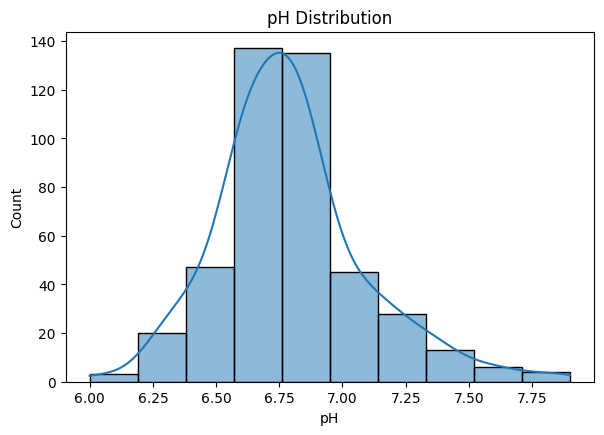

In [12]:
plt.figure(figsize=(15, 10))
# Distribution plot for pH
plt.subplot(2, 2, 2)
sns.histplot(final_data['pH'], bins=10, kde=True)
plt.title('pH Distribution')

Horizontal axis: pH values.

Vertical axis: Number of samples within each pH range.

Observations:

- Most pH values fall within the range of 6.5 to 7.5, indicating that the water in this area has a relatively stable pH and meets environmental standards.

- The distribution curve shows that most samples have a pH around 6.8, suggesting that the water environment is slightly alkaline.

Text(0.5, 1.0, 'DO Distribution')

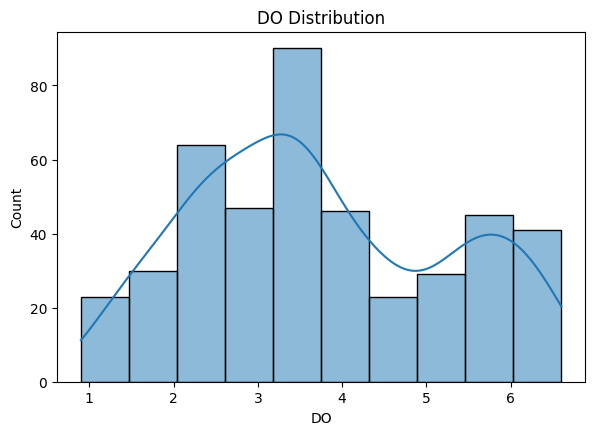

In [13]:
plt.figure(figsize=(15, 10))
# Distribution plot for DO
plt.subplot(2, 2, 3)
sns.histplot(final_data['DO'], bins=10, kde=True)
plt.title('DO Distribution')

Horizontal axis: DO values (mg/l).

Vertical axis: Number of samples within each DO range.

Observations:

- DO values show large variations, with most values concentrated between 2 and 5 mg/l.

- The distribution curve indicates that many samples have low DO, which may suggest that some areas in the study could be polluted or have lower dissolved oxygen levels, affecting the survival of aquatic organisms.

Text(0.5, 1.0, 'COD Distribution')

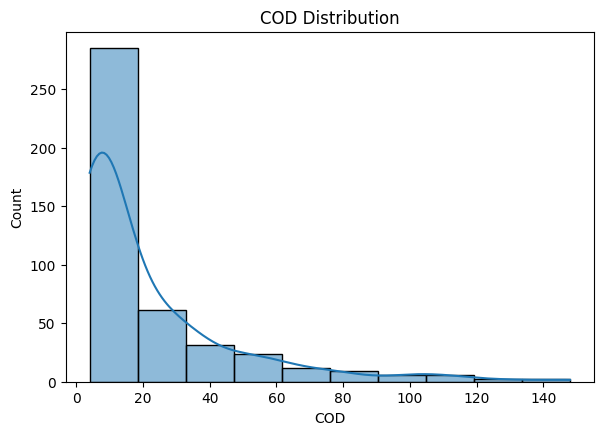

In [14]:
plt.figure(figsize=(15, 10))
# Distribution plot for COD
plt.subplot(2, 2, 3)
sns.histplot(final_data['COD'], bins=10, kde=True)
plt.title('COD Distribution')

Horizontal axis: COD values (mg/l).

Vertical axis: Number of samples within each COD range.

Observations:

- COD values are unevenly distributed, mainly concentrated in the range of 0 to 20 mg/l, with the number of samples decreasing as COD values increase.

- The distribution curve shows that most samples have low COD values, reflecting light organic pollution in many areas. However, a few samples have high COD values (> 60 mg/l), which may indicate areas heavily polluted by wastewater containing high levels of organic matter from industrial, agricultural, or domestic sources.

- Controlling these pollution sources is necessary to ensure water quality and reduce environmental pollution risks.

Text(0.5, 1.0, 'Coliform Distribution')

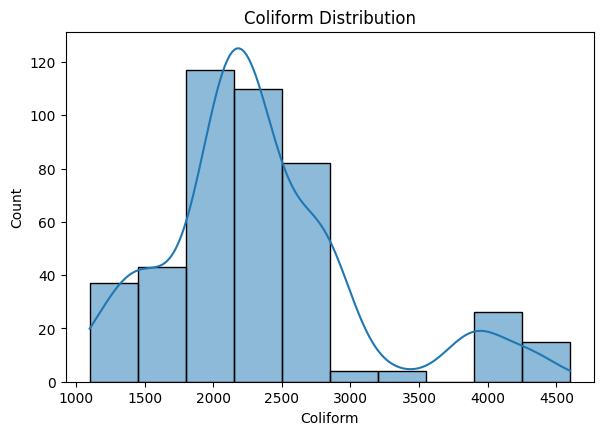

In [15]:
plt.figure(figsize=(15, 10))
# Distribution plot for Coliform
plt.subplot(2, 2, 4)
sns.histplot(final_data['Coliform'], bins=10, kde=True)
plt.title('Coliform Distribution')

Horizontal axis: Coliform values (MPN/100ml).

Vertical axis: Number of samples within each Coliform range.

Observations:

- Coliform counts in the samples are unevenly distributed, with most samples having values around 1000 to 2500 MPN/100ml.

- This indicates the potential for microbial contamination in the water, as Coliform is an important indicator of water quality and is commonly used to assess pollution levels.

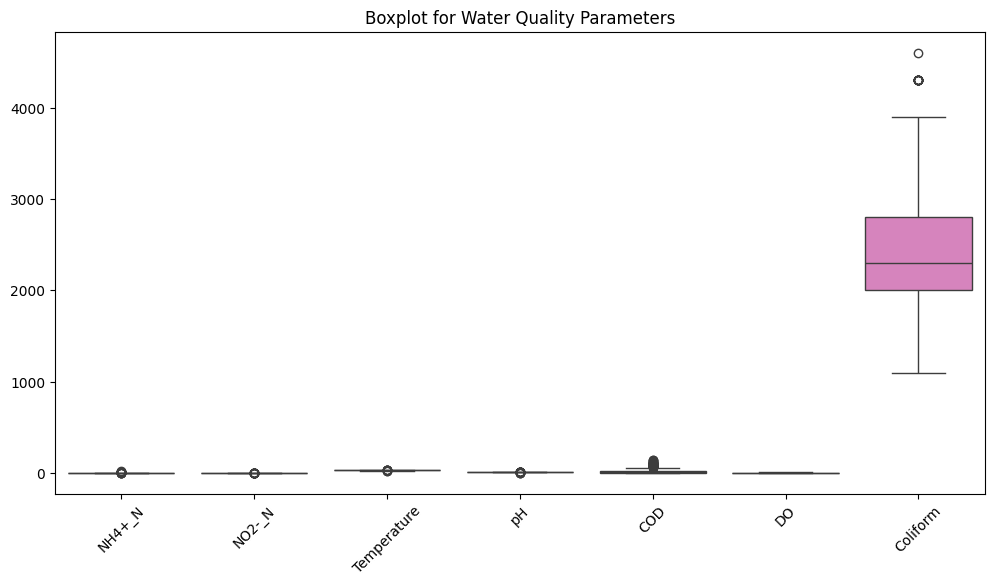

In [16]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=final_data[['NH4+_N', 'NO2-_N', 'Temperature', 'pH', 'COD', 'DO', 'Coliform']])
plt.title('Boxplot for Water Quality Parameters')
plt.xticks(rotation=45)
plt.show()

Horizontal axis: Represents the water quality parameters: NH4+_N, NO2-_N, Temperature, pH, DO, COD, and Coliform.
Vertical axis: Represents the values of each parameter.

Structure of the boxplot:

- Middle part of the box: Represents the interquartile range (IQR) of the data, where 50% of the data lies between Q1 (25th percentile) and Q3 (75th percentile).

- Line inside the box: Indicates the median value of the data.

- Whiskers: Show the distribution of data outside the IQR, typically from Q1 - 1.5 * IQR to Q3 + 1.5 * IQR.

- Outliers: Values outside the whiskers, indicating extreme values in the data.

- NH4+_N and NO2-_N: These indicators have a very narrow distribution, with most values close to 0. No clear outliers are observed, suggesting that NH4+_N and NO2-_N concentrations in the water samples are low and stable.

- Temperature: Temperature values are within a narrow range and show no clear outliers, indicating stable temperatures in the water samples with little variation.

- pH: The pH distribution is also narrow, with a median around 6.5 to 7.5. No significant outliers are observed, showing that the water quality is relatively stable in terms of pH, with no major fluctuations.

- DO: DO distribution may show some variation, but generally there are no large outliers. This indicates that the water in the study area still has sufficient dissolved oxygen for aquatic organisms, although minor fluctuations may occur.

- COD: COD distribution shows greater variation, with some outliers. This may indicate that some areas have high levels of organic pollution, which should be monitored and treated promptly to protect water quality.

- Coliform: The Coliform distribution shows large variation with some outliers. This may indicate that certain areas have higher microbial contamination. This is an important issue for water quality management, as high Coliform levels can impact public health.

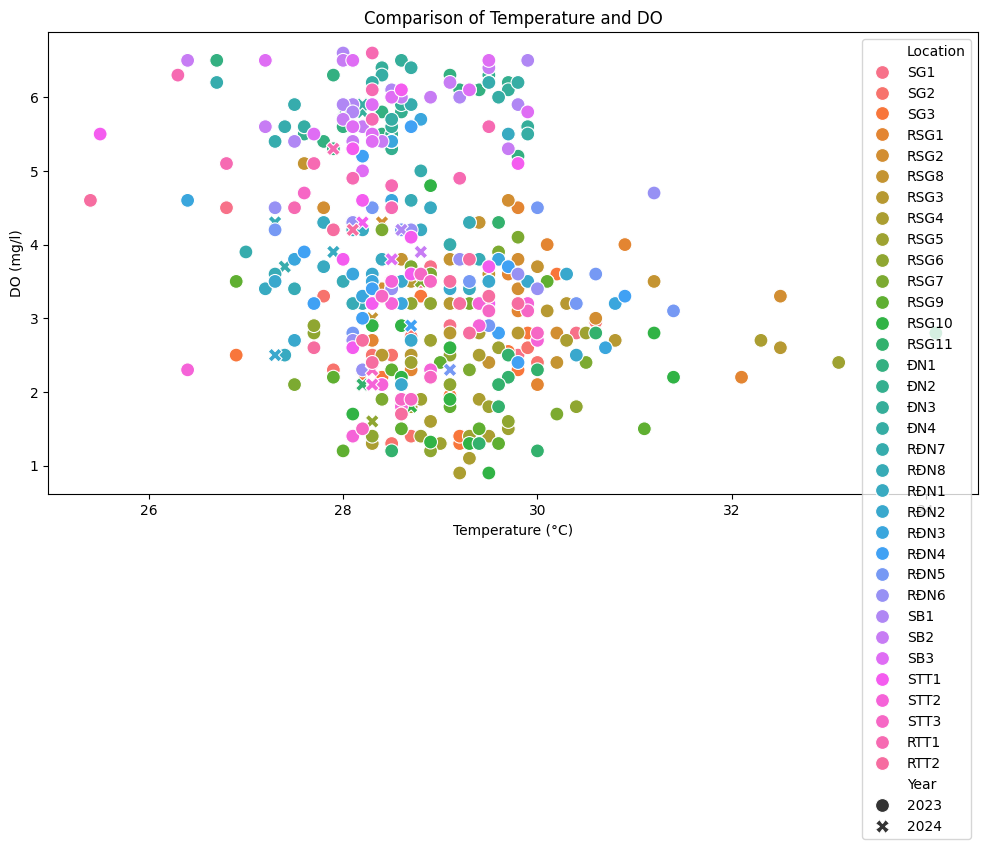

In [17]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=final_data, x='Temperature', y='DO', hue='Location', style='Year', s=100)
plt.title('Comparison of Temperature and DO')
plt.xlabel('Temperature (°C)')
plt.ylabel('DO (mg/l)')
plt.legend()
plt.show()

Horizontal axis: Represents Temperature values (°C).

Vertical axis: Represents DO levels (mg/l).

Point color: Indicates different Sampling Locations (SG1, SG2, RSG3, …), helping to distinguish between sampling areas.

Point style/size: May represent different years (2023 and 2024), showing the distribution of water samples over time.

Observations on the relationship between Temperature and DO:

- Overall trend: The plot shows that DO levels fluctuate but do not have a strong correlation with Temperature. Some samples have high temperatures but low DO levels, which may indicate that under different conditions (such as pollution or ecological structure), DO is not entirely dependent on temperature.

- Point distribution: Many points are in the temperature range of 27.5 to 29.5°C, indicating this is the common temperature range in the water samples.

- DO variability: DO values fluctuate, with many points below 3 mg/l, which may indicate that the water environment could be oxygen-deficient, affecting the survival of aquatic organisms.

# 3. Feature Engineering (20%)


---





Apply various feature engineering techniques, covered in the lectures and practicals.

Hint:
* Binning
* Encoding
* Scaling
* Feature selection

In [18]:
# <<< Your code here >>>

# 4. Classifier Training (20%)


---


Utilise the sklearn Python library to train a ML model (e.g.decision tree classifier). Your process should start with splitting your dataset into input features (X) and a target feature (y). Next, divide the data into 70% training and 30% testing subsets. Train your model on the training dataset and evaluate using test dataset with appropriate metrics. Aim to achieve higher accuracy e.g. more than 70% accuracy using your model.

## 4.1. Data Splitting (5%)

In [19]:
# Split the data into training and testing sets
from sklearn.model_selection import train_test_split 

# Separate X and y
X = final_data[['NH4+_N', 'NO2-_N', 'DO', 'Coliform', 'COD']]  # Features
y = final_data['WQI']  # WQI index

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Number of samples in X:", len(X))
print("Number of samples in y:", len(y))

Number of samples in X: 438
Number of samples in y: 438


## 4.2. Model Training (10%)

In [20]:
# Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predictions on the test set
rf_pred = rf_model.predict(X_test)

# Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predictions on the test set
lr_pred = lr_model.predict(X_test)

# Gradient Boosting model
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)

# Predictions on the test set
gb_pred = gb_model.predict(X_test)

## 4.3. Model Evaluation (5%)

In [21]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Random Forest - MSE:", mean_squared_error(y_test, rf_pred))
print("Random Forest - RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("Random Forest - MAE:", mean_absolute_error(y_test, rf_pred))
print("Random Forest - R^2:", r2_score(y_test, rf_pred))

print("\n" + "="*50 + "\n")

print("Linear Regression - MSE:", mean_squared_error(y_test, lr_pred))
print("Linear Regression - RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("Linear Regression - MAE:", mean_absolute_error(y_test, lr_pred))
print("Linear Regression - R^2:", r2_score(y_test, lr_pred))

print("\n" + "="*50 + "\n")

print("Gradient Boosting - MSE:", mean_squared_error(y_test, gb_pred))
print("Gradient Boosting - RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("Gradient Boosting - MAE:", mean_absolute_error(y_test, gb_pred))
print("Gradient Boosting - R^2:", r2_score(y_test, gb_pred))

Random Forest - MSE: 0.19202013565774367
Random Forest - RMSE: 0.43820102197250027
Random Forest - MAE: 0.2816224640901109
Random Forest - R^2: 0.9815468443277742


Linear Regression - MSE: 4.193743789875456
Linear Regression - RMSE: 2.0478632253828515
Linear Regression - MAE: 1.3886119050836299
Linear Regression - R^2: 0.596980771110702


Gradient Boosting - MSE: 0.10836203737881121
Gradient Boosting - RMSE: 0.3291838959894776
Gradient Boosting - MAE: 0.1802503980786306
Gradient Boosting - R^2: 0.9895863965627288


# 5. Feature Importance (10%)


---

Assess the importance of features within your decision tree model. Provide commentary on the reliability of your model's results based on the feature importance scores.

In [22]:
# <<< Your code here >>>

# 6. Apply GridSearchCV


---

In [23]:
# Define the parameter grid for RandomForest
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_split': [5, 10, 15]
}

# Initialize GridSearchCV for RandomForest
rf_grid_search = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=5, n_jobs=-1)
rf_grid_search.fit(X_train, y_train)

# Get the best hyperparameters from GridSearchCV
best_rf_params = rf_grid_search.best_params_
print("Best parameters for RandomForest:", best_rf_params)

Best parameters for RandomForest: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}


In [24]:
# Define the parameter grid for GradientBoosting
gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# Initialize GridSearchCV for GradientBoosting
gb_grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_param_grid, cv=5, n_jobs=-1)
gb_grid_search.fit(X_train, y_train)

# Get the best hyperparameters from GridSearchCV
best_gb_params = gb_grid_search.best_params_
print("Best parameters for GradientBoosting:", best_gb_params)

Best parameters for GradientBoosting: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}


In [25]:
# Optimized base models
optimized_models = {
    'RandomForest': RandomForestRegressor(**best_rf_params),
    'LinearRegression': LinearRegression(),
    'GradientBoosting': GradientBoostingRegressor(**best_gb_params)
}

# Meta-model - this is the model for learning the ensemble
meta_model = LinearRegression()

# Create the StackingRegressor with base models and the meta-model
stacking_model = StackingRegressor(
    estimators=[('rf', optimized_models['RandomForest']),
                ('lr', optimized_models['LinearRegression']),
                ('gb', optimized_models['GradientBoosting'])],
    final_estimator=meta_model
)

# Train the stacking model on the training data (X_train and y_train)
stacking_model.fit(X_train, y_train)

# Predict on the test data (X_test)
sm_pred = stacking_model.predict(X_test)

In [26]:
print("Stacking Model - MSE:", mean_squared_error(y_test, sm_pred))
print("Stacking Model - RMSE:", np.sqrt(mean_squared_error(y_test, sm_pred)))
print("Stacking Model - MAE:", mean_absolute_error(y_test, sm_pred))
print("Stacking Model - R^2:", r2_score(y_test, sm_pred))

Stacking Model - MSE: 0.11050678151646899
Stacking Model - RMSE: 0.332425602979778
Stacking Model - MAE: 0.18528833346672832
Stacking Model - R^2: 0.9893802864206142


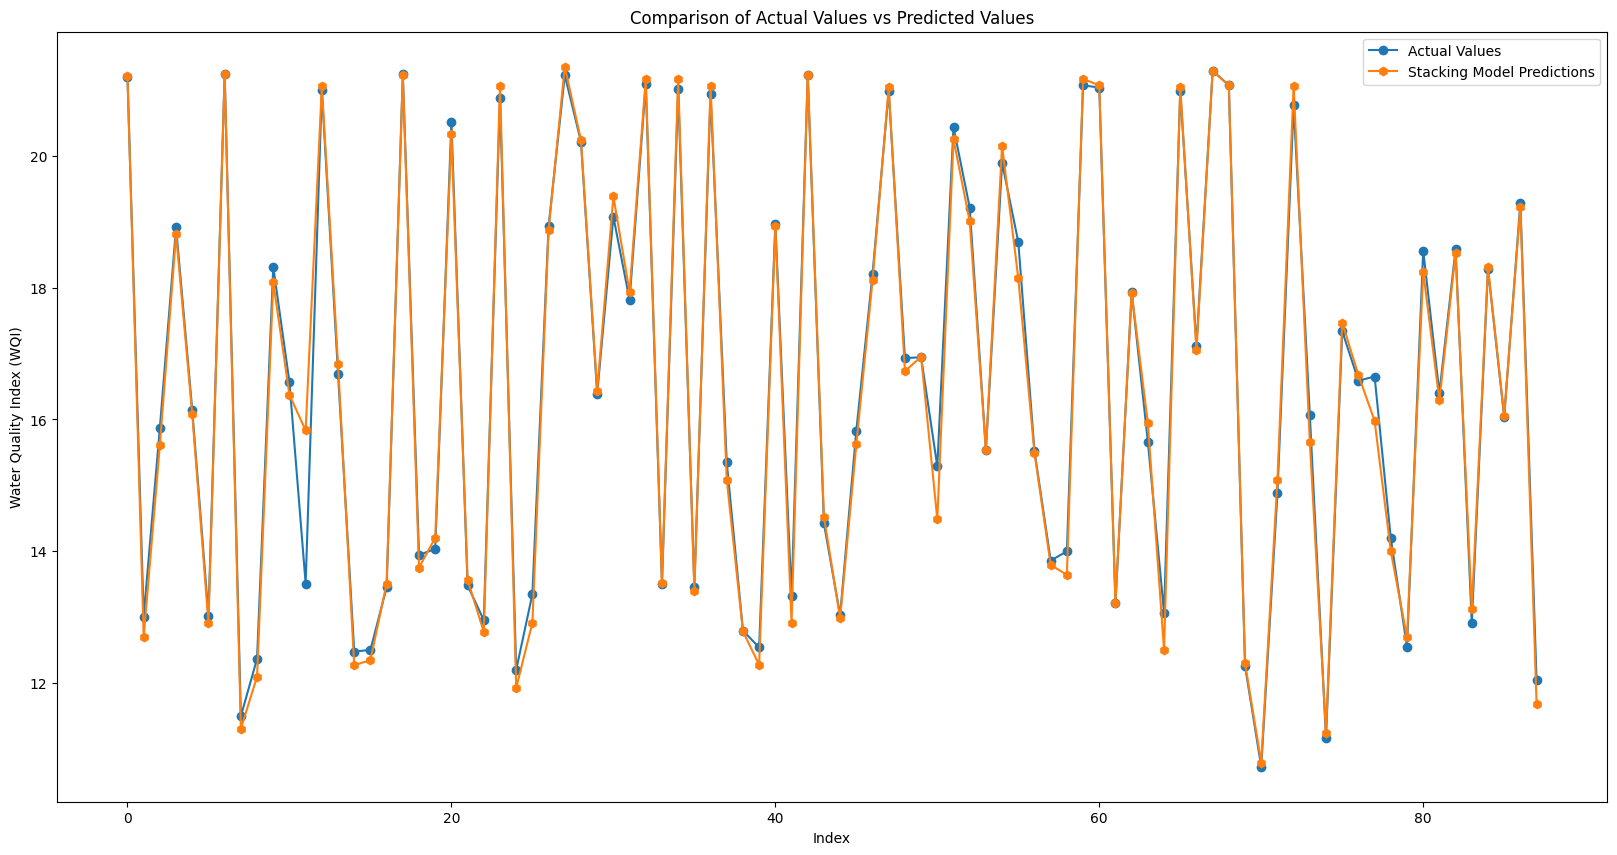

In [27]:
plt.figure(figsize=(20, 10))
plt.plot(y_test.values, label='Actual Values', marker='o')
plt.plot(sm_pred, label='Stacking Model Predictions', marker='h')
plt.title('Comparison of Actual Values vs Predicted Values')
plt.xlabel('Index')
plt.ylabel('Water Quality Index (WQI)')
plt.legend()
plt.show()

Horizontal axis: Represents the sample index, showing the order of points in the test set.

Vertical axis: Represents the Water Quality Index (WQI).

Data points:

- Actual values (circles): Represent the true WQI values.

- Predictions from the Random Forest model (crosses): Points represent WQI values predicted by the Random Forest model.

- Predictions from the Linear Regression model (squares): Points represent WQI values predicted by the Linear Regression model.

Observations on the relationship between predictions and actual values:

- Similarity: Both models attempt to track the fluctuations of the actual values. However, there are some points where the models do not achieve high accuracy.

- Random Forest: Relatively close to the actual values. Although there are a few deviations, the model generally reflects the trends in the real data well. This model often has higher accuracy and can capture data variability better than linear regression, likely due to its ability to handle nonlinear relationships.

- Linear Regression: Shows a clear difference compared to the actual values. The model may not capture all fluctuations accurately, especially at data points with extreme values. This may be due to the assumption of a linear relationship between independent and dependent variables.

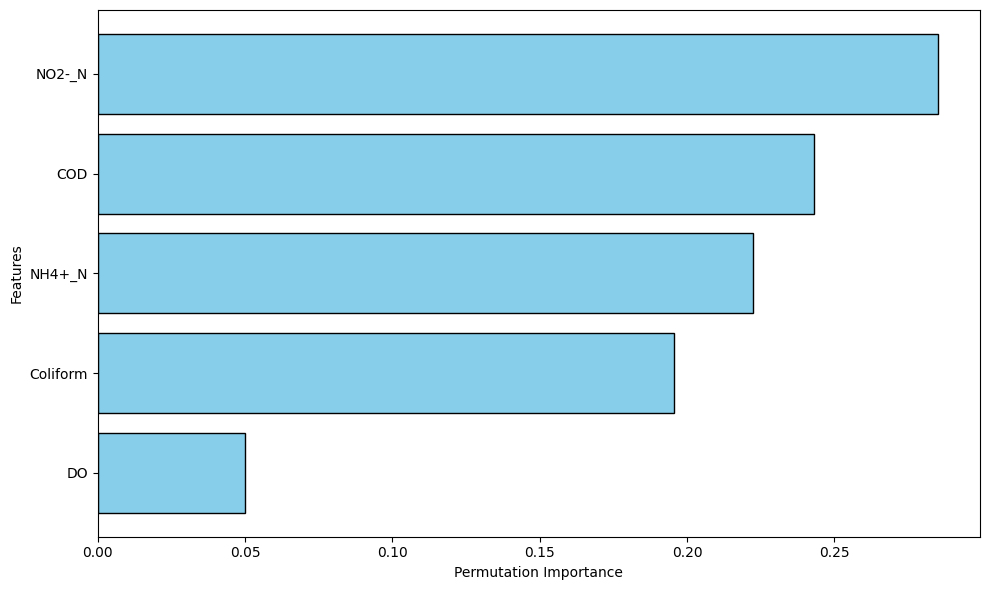

In [28]:
# Calculate Permutation Importance
perm_importance = permutation_importance(stacking_model, X_test, y_test, n_repeats=30, random_state=42)

# Get mean values and sort by importance
sorted_idx = perm_importance.importances_mean.argsort()

# Plot the chart
plt.figure(figsize=(10, 6))
plt.barh(X_test.columns[sorted_idx], perm_importance.importances_mean[sorted_idx], color="skyblue", edgecolor="black")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

The above chart shows the main pollutants affecting water quality. The most important factor is NO2-N (Nitrite), primarily originating from agricultural fertilizers, untreated livestock and domestic wastewater, and industrial activities, indicating severe chemical pollution. Next is NH4+-N (Ammonium), a key indicator reflecting organic decomposition and pollution from agricultural and livestock waste. COD (Chemical Oxygen Demand) also plays a significant role, reflecting the presence of organic and hard-to-degrade chemicals in water, often from industrial, agricultural, and domestic wastewater.

Additionally, Coliform is a microbiological indicator showing the presence of bacteria from untreated domestic and livestock wastewater, with a substantial influence on assessing microbial contamination. DO (Dissolved Oxygen), although having a lower impact, remains an important factor related to the water’s ability to support aquatic life. Finally, pH has the smallest impact in the chart but still plays a critical role in maintaining the chemical balance of water. These indicators provide essential information for identifying the factors that require intervention to improve water quality.

The proposed model combines three algorithms — Linear Regression, RandomForestRegressor, and GradientBoostingRegressor — to optimize water quality prediction performance. The Permutation Feature Importance method is applied to evaluate the importance of each parameter by shuffling the values of each feature in the test data and measuring the effect on model performance. The analysis results indicate that the main influential indicators include NO2-N, NH4+-N, COD, Coliform, DO, and pH. Among them, NO2-N and NH4+-N are the most significant factors, mainly originating from agricultural fertilizers, livestock, and domestic wastewater. COD reflects the level of organic pollution from industrial and domestic wastewater, while Coliform indicates the presence of bacteria from untreated wastewater. DO is affected by organic pollution, and pH is important for maintaining chemical balance in water.

To improve water quality, priority should be given to reducing factors such as NO2-N, NH4+-N, COD, and Coliform through the management of agricultural fertilizers and treatment of industrial and domestic wastewater. Additionally, controlling organic pollution (COD, BOD5) will help improve dissolved oxygen levels (DO) while maintaining pH stability. These solutions, combined with the predictive results from the model, will support authorities in developing appropriate strategies to enhance the Water Quality Index (WQI).

# 6. Make inference


---

Predictions for the Future

In [31]:
future_data = pd.DataFrame({
    'NH4+_N': [0.03, 0.025, 0.01],
    'NO2-_N': [0.05, 0.06, 0.001],
    'DO': [8, 4, 6],
    'Coliform': [10, 20, 100],
    'COD': [5, 8, 1]
})

In [32]:
# Step 2: Predict WQI for future data
future_predictions_rf = rf_model.predict(future_data)
future_predictions_lr = lr_model.predict(future_data)
future_predictions_gb = gb_model.predict(future_data)
future_predictions_sm = stacking_model.predict(future_data)

# Add prediction results to the DataFrame
future_data['WQI_RF'] = future_predictions_rf
future_data['WQI_LR'] = future_predictions_lr
future_data['WQI_GB'] = future_predictions_gb
future_data['WQI_SM'] = future_predictions_sm

# Display predictions for 2025
print("Predicted WQI for 2025:")
print(future_data)

Predicted WQI for 2025:
   NH4+_N  NO2-_N  DO  Coliform  COD     WQI_RF     WQI_LR     WQI_GB  \
0   0.030   0.050   8        10    5  20.753207  24.284275  20.248917   
1   0.025   0.060   4        20    8  18.992692  20.753823  19.089353   
2   0.010   0.001   6       100    1  21.148233  23.028422  21.098139   

      WQI_SM  
0  20.323204  
1  19.035148  
2  21.197900  


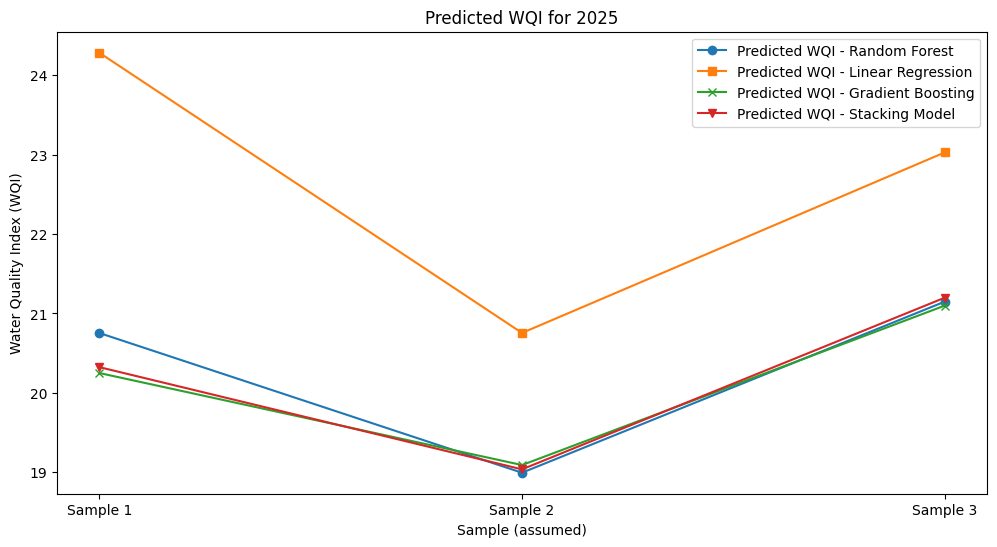

In [33]:
# Plot predictions for 2025
plt.figure(figsize=(12, 6))
plt.plot(future_data.index, future_data['WQI_RF'], label='Predicted WQI - Random Forest', marker='o')
plt.plot(future_data.index, future_data['WQI_LR'], label='Predicted WQI - Linear Regression', marker='s')
plt.plot(future_data.index, future_data['WQI_GB'], label='Predicted WQI - Gradient Boosting', marker='x')
plt.plot(future_data.index, future_data['WQI_SM'], label='Predicted WQI - Stacking Model', marker='v')
plt.title('Predicted WQI for 2025')
plt.xlabel('Sample (assumed)')
plt.ylabel('Water Quality Index (WQI)')
plt.xticks(future_data.index, ['Sample 1', 'Sample 2', 'Sample 3'])
plt.legend()
plt.show()

Horizontal axis (X): Represents the sample index, showing the order of points in the test set.

Vertical axis (Y): Represents the Water Quality Index (WQI).

Data points:

- Actual values (circles): Represent the true WQI values.

- Predictions from the Random Forest model (crosses): Points represent WQI values predicted by the Random Forest model.

- Predictions from the Linear Regression model (squares): Points represent WQI values predicted by the Linear Regression model.

- Predictions from the Gradient Boosting and Stacking Model: Points appear on the chart with stability and similarity, indicating the effectiveness of nonlinear models.

Similarity:

All four models (Random Forest, Linear Regression, Gradient Boosting, and Stacking Model) predict WQI for the samples in 2025 with similar values (except for Linear Regression). This shows that the models are capturing a general trend in the water quality data.

Trend:

Most models show a slight decrease from Sample 1 to Sample 2 and an increase at Sample 3. This may indicate fluctuations in water quality among the samples, potentially reflecting changes in environmental conditions or pollutant sources.

Accuracy:

Gradient Boosting and the Stacking Model tend to produce more stable and consistent predictions compared to Linear Regression, which shows larger discrepancies between samples. Random Forest also produces stable results, indicating suitability for nonlinear data. Linear Regression is less effective when handling complex or nonlinear data.

Specific values:

Comparing specific values in the chart, Gradient Boosting, Random Forest, and the Stacking Model give similar predictions, ranging between 19–21 for all three samples. Linear Regression shows greater differences, especially for Sample 1 and Sample 3 (exceeding 24). This emphasizes the necessity of applying nonlinear models for more accurate predictions.